In [ ]:
%pip install -q "anndata==0.11.4" "scanpy==1.11.5" "pandas==2.2.3" "zarr<3" igraph leidenalg

In [ ]:
import pandas as pd
import scanpy as sc
from importlib.metadata import version

print("Pandas:", version("pandas"))
print("AnnData:", version("anndata"))
print("Scanpy:", version("scanpy"))

Pandas: 2.2.3
AnnData: 0.11.4
Scanpy: 1.11.5


In [ ]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sc.settings.verbosity = 2 # print informational messages and progress

adata = sc.datasets.pbmc3k()

print(adata)
print("Cells:", adata.n_obs) # number of cells
print("Genes:", adata.n_vars) # number of genes

try downloading from url
https://falexwolf.de/data/pbmc3k_raw.h5ad
... this may take a while but only happens once


  0%|          | 0.00/5.58M [00:00<?, ?B/s]

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
Cells: 2700
Genes: 32738


### Number of Genes Detected per Cell (`n_genes_by_counts`)

`n_genes_by_counts` is calculated from the count matrix. It is not the count of a single entry; instead, it counts how many genes have a nonzero value in each cell.

### Example

Suppose the count matrix looks like this:

| Cell | Gene A | Gene B | Gene C | Gene D |
|---|---:|---:|---:|---:|
| Cell 1 | 5 | 2 | 0 | 3 |
| Cell 2 | 0 | 4 | 0 | 0 |
| Cell 3 | 1 | 0 | 7 | 2 |

Scanpy counts the genes with values greater than zero in each row:

- **Cell 1:** `n_genes_by_counts = 3` (Genes A, B and D).
- **Cell 2:** `n_genes_by_counts = 1` (Gene B).
- **Cell 3:** `n_genes_by_counts = 3` (Genes A, C and D).

### Key Takeaway

A gene is considered detected when its observed count is greater than zero. Therefore, `n_genes_by_counts` measures the number of detected genes in each cell, not the total number of RNA counts.

In [ ]:
# Identify mitochondrial genes in human data
adata.var["mt"] = adata.var_names.str.startswith("MT-")

# Calculate QC metrics for each cell
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    inplace=True
)
# PBMC 3k dataset with Scanpy, the count matrix contains UMI-based gene counts.
# Inspect the first few cells
adata.obs[
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
].head()

,n_genes_by_counts,total_counts,pct_counts_mt
index,,,
AAACATACAACCAC-1,781,2421.0,3.015283
AAACATTGAGCTAC-1,1352,4903.0,3.793596
AAACATTGATCAGC-1,1131,3149.0,0.889171
AAACCGTGCTTCCG-1,960,2639.0,1.743085
AAACCGTGTATGCG-1,522,981.0,1.223242


In [ ]:
# which genes in your dataset are mitochondrial genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")
print(adata.var["mt"].head())
print(adata.var_names[adata.var["mt"]][:5])


index
MIR1302-10      False
FAM138A         False
OR4F5           False
RP11-34P13.7    False
RP11-34P13.8    False
Name: mt, dtype: bool
Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8'], dtype='object', name='index')


### Identifying Mitochondrial Genes

- `adata.var_names`: Retrieves the names of all genes in the dataset.
- `.str.startswith("MT-")`: Checks whether each gene name starts with `"MT-"` and returns `True` or `False`.
- `adata.var["mt"] =`: Stores these Boolean results in a new column called `mt` in the gene metadata table.

### AnnData Structure

- **`adata.obs`** stores cell-level information, such as QC metrics and cluster labels.
- **`adata.var`** stores gene-level information, such as gene names and whether a gene is mitochondrial.

### Key Takeaway

The `mt` column identifies mitochondrial genes for downstream QC calculations. It does not remove these genes from the dataset.

**Note:** The `"MT-"` prefix is commonly used for human mitochondrial genes. Other organisms may use different naming conventions.

### Understanding QC Metrics

- **`n_genes_by_counts`:** Number of genes detected in each cell.
- **`total_counts`:** Total observed RNA counts across all genes in each cell.
- **`pct_counts_mt`:** Percentage of the cell's total counts that come from mitochondrial genes.

These metrics help assess cell quality. The key difference is that `n_genes_by_counts` counts detected genes, while `total_counts` measures the total observed counts.

### Example

Suppose a cell has these observed counts:

| Gene | Observed counts |
|---|---:|
| Gene A | 5 |
| Gene B | 3 |
| Gene C | 0 |
| Gene D | 2 |
| Gene E | 0 |
| **Total** | **10** |

**1. `n_genes_by_counts` = 3**

Three genes have at least one observed count: A, B and D.

**2. `total_counts` = 10**

The total is the sum of all observed counts: 5 + 3 + 0 + 2 + 0 = 10.

**3. `pct_counts_mt` = 20% (example)**

If 2 of the 10 counts come from mitochondrial genes, the mitochondrial percentage is 20%.

### Why Do We Need Both Gene Counts and Total Counts?

| Metric | Cell A | Cell B |
|---|---:|---:|
| Detected genes | 1,000 | 1,000 |
| Total counts | 2,000 | 10,000 |
| Average counts per detected gene | 2 | 10 |

Both cells have the same number of detected genes, but Cell B has five times as many observed counts. This can reflect differences in RNA abundance, RNA capture or sequencing depth.

### Interpreting QC Metrics

- **Low `n_genes_by_counts`:** May indicate a low-quality cell, an empty droplet or a cell with little RNA.
- **Low `total_counts`:** May indicate low sequencing depth or low RNA content.
- **High `pct_counts_mt`:** May indicate a damaged or stressed cell, although normal values vary by cell type and tissue.

**Key takeaway:** These metrics help identify potentially low-quality cells, but thresholds should be chosen based on the dataset rather than applied universally.

Y-axis (vertical): the number of detected genes per cell.

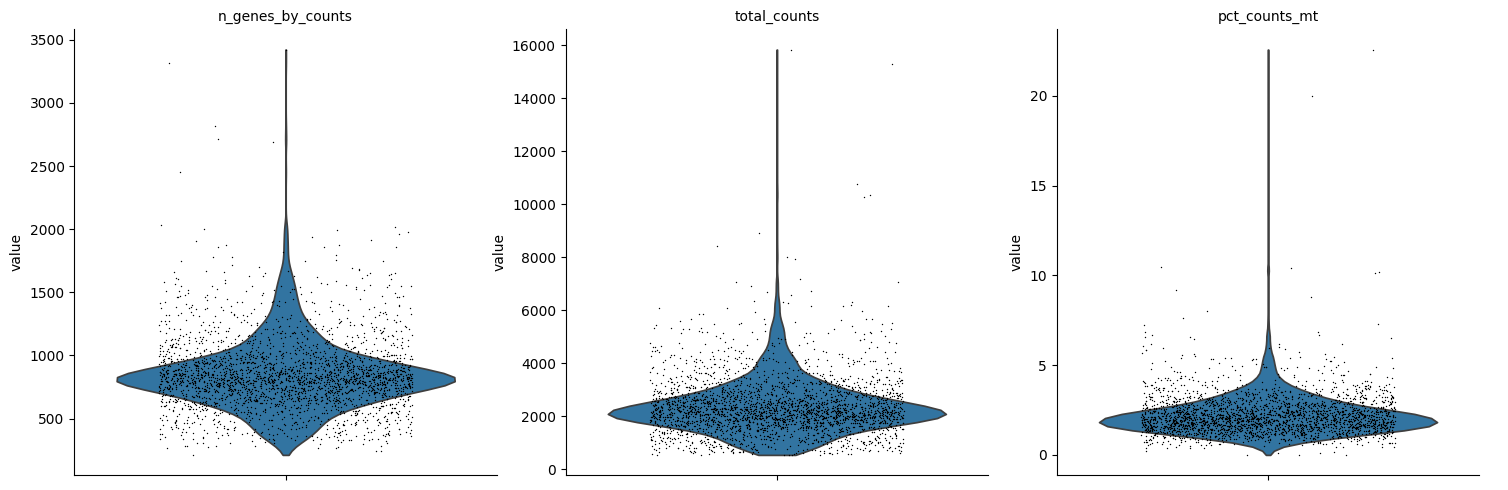

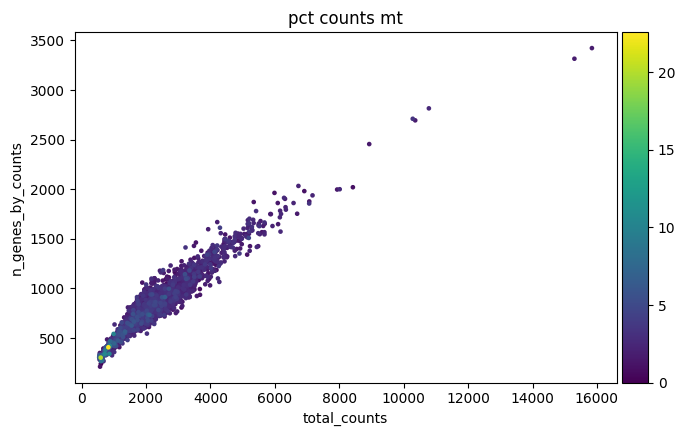

In [ ]:
# Visualize cell quality
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.3,
    multi_panel=True
)

sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts",
    color="pct_counts_mt"
)

**Plots before filtering**

 Cells with very few detected genes may be low quality.

Cells with unusually high counts or gene numbers may be doublets.

 High mitochondrial percentages can indicate stressed or damaged cells, although this depends on the tissue and experiment.

In [ ]:
#Filter cells and genes

print("Before filtering:", adata.shape)

# Remove cells with fewer than 200 detected genes
sc.pp.filter_cells(adata, min_genes=200)

# Remove genes detected in fewer than 3 cells
sc.pp.filter_genes(adata, min_cells=3)

# Apply a provisional mitochondrial threshold
# cells whose mitochondrial counts make up 15% or more of their total counts.
adata = adata[adata.obs["pct_counts_mt"] < 15].copy() #cell level filtering, because these types of cells are probably damaged

print("After filtering:", adata.shape)

Before filtering: (2700, 32738)
filtered out 19024 genes that are detected in less than 3 cells
After filtering: (2698, 13714)


In [ ]:
# Save raw counts and normalize

# Preserve the count matrix before transforming it
adata.layers["counts"] = adata.X.copy()

# Normalize each cell to a total of 10,000 counts
sc.pp.normalize_total(adata, target_sum=1e4)

# Apply log(1 + x) transformation
sc.pp.log1p(adata)

print(adata)

normalizing counts per cell
    finished (0:00:02)
AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'log1p'
    layers: 'counts'


Why do we do this?
- **Normalization** reduces differences caused by cells having different total numbers of observed counts.
- **Log transformation** compresses the range of values so that very large counts have less influence.
We keep the original counts in adata.layers["counts"] because some later analyses need them.

extracting highly variable genes
    finished (0:00:00)
Highly variable genes: 2000


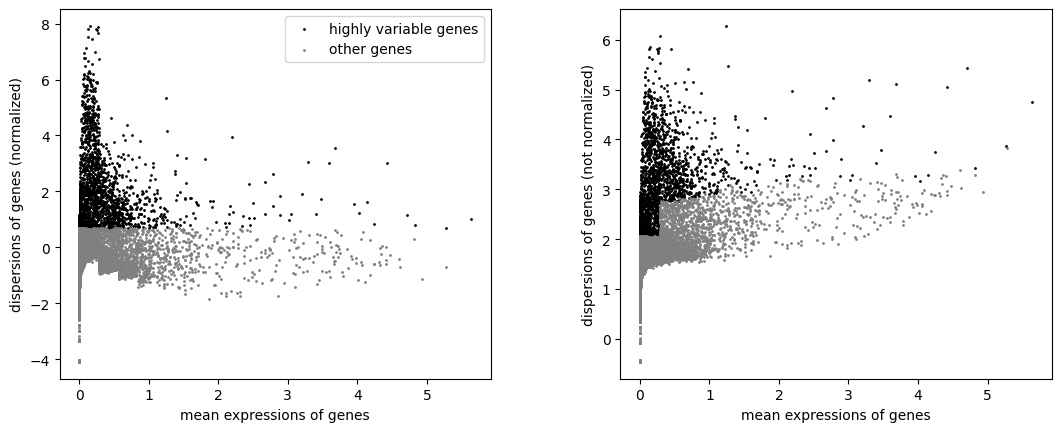

In [ ]:
# Select highly variable genes
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat"
)

print(
    "Highly variable genes:",
    adata.var["highly_variable"].sum()
)

sc.pl.highly_variable_genes(adata)

<div style="font-family: 'Times New Roman'; color: #1F4E79;"> Highly variable genes show substantial variation across cells. They are often useful for discovering cell populations, though variation can also reflect technical effects.
We mark these genes rather than removing the other genes from the dataset.
</div>

In [ ]:
adata.write_h5ad("pbmc3k_preprocessed.h5ad")

print("Saved processed dataset.")

Saved processed dataset.


### Exporting the preprocessed dataset for the next notebook

The next notebook starts from the processed AnnData object saved above. Download this `.h5ad` file and upload it when prompted at the beginning of Notebook 2. This keeps the preprocessing steps separate while allowing the clustering notebook to use the same processed data.

In [ ]:
from google.colab import files

files.download("pbmc3k_preprocessed.h5ad")